In [1]:
import os
import regionmask
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import ttest_ind
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from shapely.errors import GEOSException

In [2]:
def to_month_start_on_time(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month.
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)

In [3]:
out = "/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed"
era5_path = os.path.join(out, "era5_data.nc")
era5_data = xr.open_dataset(era5_path)
# subset ERA5 from 2002-04-01 onwards (no upper bound yet)
era5_data = era5_data.sel(time=slice("2002-04-01", None))
era5_data = to_month_start_on_time(era5_data)
era5_data

<xarray.Dataset> Size: 5GB
Dimensions:  (time: 273, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-04-01 2002-05-01 ... 2024-12-01
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    swe      (time, lat, lon) float32 1GB ...
    t2m      (time, lat, lon) float32 1GB ...
    ppt      (time, lat, lon) float32 1GB ...
    eto      (time, lat, lon) float32 1GB ...

In [4]:
# Compute resolution (in degrees)
dlat = np.abs(era5_data.lat[1] - era5_data.lat[0]).item()
dlon = np.abs(era5_data.lon[1] - era5_data.lon[0]).item()
print(f"ERA5 grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

ERA5 grid spacing: 0.250° lat × 0.250° lon


In [5]:
swsa = xr.open_dataset("/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed/swsa.nc")["sws"]
swsa = swsa.sel(time=~swsa.indexes["time"].duplicated())
swsa

<xarray.DataArray 'sws' (time: 238, lat: 360, lon: 720)> Size: 247MB
[61689600 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-04-01 2002-05-01 ... 2024-12-01
  * lat      (lat) float64 3kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float64 6kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
    number   int64 8B ...
    expver   (time) <U4 4kB ...

In [6]:
# Compute resolution (in degrees)
dlat = np.abs(swsa.lat[1] - swsa.lat[0]).item()
dlon = np.abs(swsa.lon[1] - swsa.lon[0]).item()
print(f"grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

grid spacing: 0.500° lat × 0.500° lon


In [7]:
def show_time_info(da, name):
    t = pd.to_datetime(da.indexes["time"])
    print(f"{name}: n={len(t)}, min={t.min()}, max={t.max()}, dupes={t.duplicated().sum()}")

show_time_info(era5_data["swe"], "era5 swe")
show_time_info(era5_data["eto"], "era5 eto")
show_time_info(swsa, "sws")

t = pd.to_datetime(swsa.indexes["time"])
dup_mask  = t.duplicated(keep=False)
dup_times = pd.Series(t[dup_mask]).value_counts().sort_index()
print(dup_times)          # which months are duplicated and how many times

era5 swe: n=273, min=2002-04-01 00:00:00, max=2024-12-01 00:00:00, dupes=0
era5 eto: n=273, min=2002-04-01 00:00:00, max=2024-12-01 00:00:00, dupes=0
sws: n=238, min=2002-04-01 00:00:00, max=2024-12-01 00:00:00, dupes=0
Series([], Name: count, dtype: int64)


In [8]:
# hydrobasins level 3
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")

hb.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

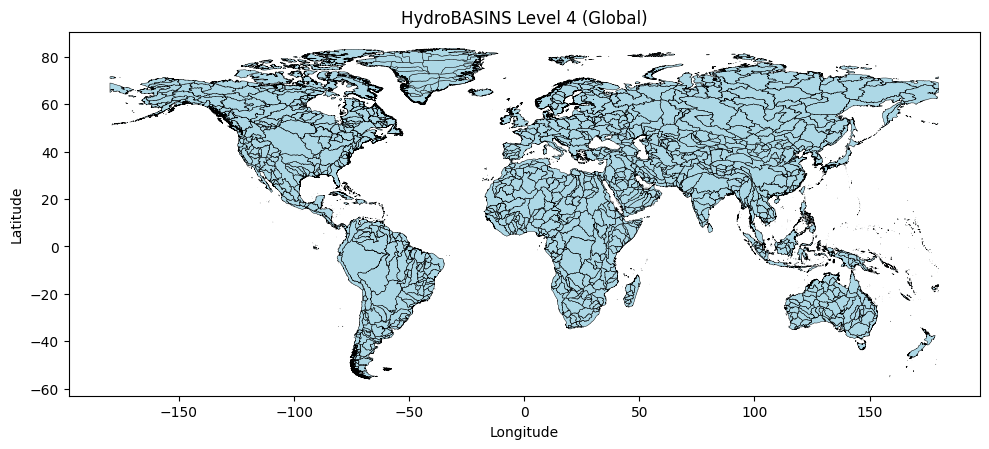

In [9]:
# Plot hydrobasins
fig, ax = plt.subplots(figsize=(10, 6))
hb.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4 (Global)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [10]:
hb_simple = hb.copy()
hb_simple["geometry"] = hb.geometry.simplify(0.01, preserve_topology=True)

# Fix invalid geometries introduced by simplify
hb_simple["geometry"] = hb_simple.geometry.buffer(0)

# Get ALL MAIN_BAS IDs (sorted)
main_ids = np.sort(hb_simple["MAIN_BAS"].unique())

Plotting MAIN_BAS = 1040000010


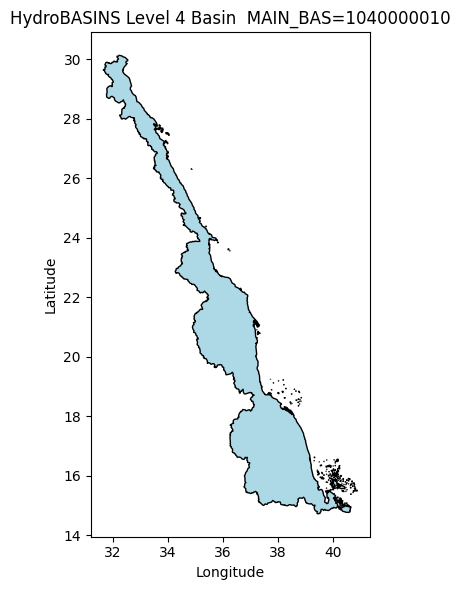

Plotting MAIN_BAS = 9040018060


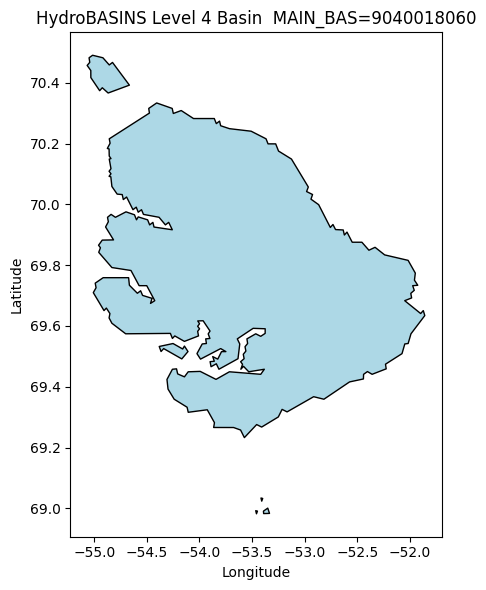

In [11]:
# Identify first and last basins
first_id = main_ids[0]
last_id  = main_ids[-1]

for main_id in main_ids:
    basin = hb_simple[hb_simple["MAIN_BAS"] == main_id]

    # Only plot first and last basins
    if main_id in [first_id, last_id]:
        print(f"Plotting MAIN_BAS = {main_id}")

        fig, ax = plt.subplots(figsize=(8, 6))
        basin.plot(ax=ax, color="lightblue", edgecolor="black")

        ax.set_title(f"HydroBASINS Level 4 Basin  MAIN_BAS={main_id}", fontsize=12)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

        plt.tight_layout()
        plt.show()

In [12]:
geoms   = []
names   = []
abbrevs = []
main_ids_valid = []

for mid in main_ids:
    basin = hb_simple[hb_simple["MAIN_BAS"] == mid]

    try:
        # dissolve polygons for this MAIN_BAS
        geom = basin.geometry.union_all()
        # clean again just in case
        geom = geom.buffer(0)
        if geom.is_empty:
            print(f"Skipping MAIN_BAS={mid} (empty after buffer)")
            continue
    except GEOSException as e:
        print(f"Skipping MAIN_BAS={mid} due to topology error: {e}")
        continue
    
    geoms.append(geom)
    names.append(f"basin_{mid}")
    abbrevs.append(str(mid))
    main_ids_valid.append(mid) 

In [13]:
regions = regionmask.Regions(geoms, names=names, abbrevs=abbrevs)
regions

<regionmask.Regions 'unnamed'>
overlap:  None

Regions:
  0 1040000010 basin_1040000010
  1 1040003990 basin_1040003990
  2 1040006850 basin_1040006850
  3 1040006860 basin_1040006860
  4 1040007000 basin_1040007000
 ..        ...              ...
974 9040016100 basin_9040016100
975 9040016110 basin_9040016110
976 9040017460 basin_9040017460
977 9040017470 basin_9040017470
978 9040018060 basin_9040018060

[979 regions]

In [14]:
main_ids_valid_all = main_ids_valid.copy()  # keep original order used to build `regions`
basin_to_region_index = {bid: i for i, bid in enumerate(main_ids_valid_all)}

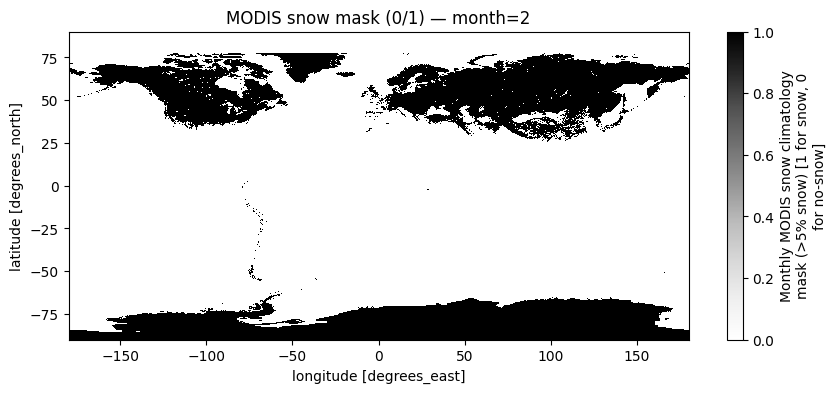

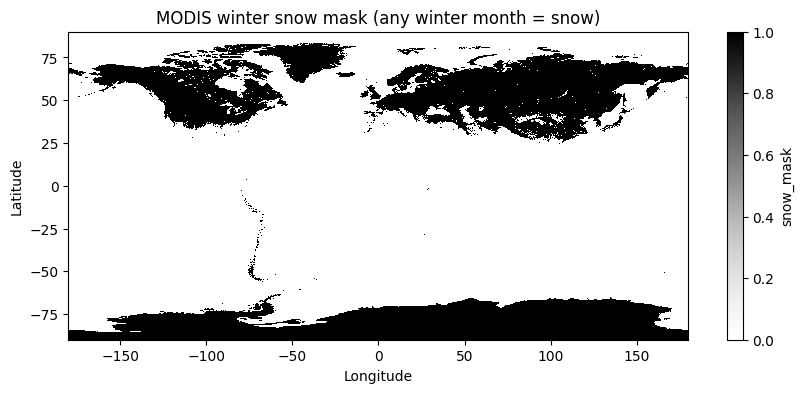

In [15]:
# load snow mask climatology (MODIS NSIDC)
snow_path = "/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_mask_monthly_0p05deg.nc"
snow = xr.open_dataset(snow_path)

# pick the data_var snow_mask
snow_var_name = list(snow.data_vars)[0]
snow_clim = snow[snow_var_name]  # dims: month, lat, lon, values 0/1

# pick snow months Dec–Mar
snow_winter = snow_clim.sel(month=[12, 1, 2, 3])

snow_winter.isel(month=2).plot(
    x="lon", y="lat",
    cmap="Greys",
    vmin=0, vmax=1,
    figsize=(10, 4)
)
plt.title(f"MODIS snow mask (0/1) — month={int(snow_winter.month.values[2])}")
plt.show()

# # 2D boolean map: True where it is snow-covered in any winter month
snow_mask = (snow_winter == 1).any(dim="month")

snow_mask.plot(
    x="lon", y="lat",
    cmap="Greys",
    figsize=(10, 4),
    add_colorbar=True
)

plt.title("MODIS winter snow mask (any winter month = snow)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [16]:
# load cropland (2019)
crop_path = "/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc"
crop = xr.open_dataset(crop_path)
crop_var_name = list(crop.data_vars)[1]
cropland = crop[crop_var_name]  # e.g., cropland fraction

# If coordinates are named x/y, rename to lon/lat once:
if "x" in cropland.dims and "y" in cropland.dims:
    cropland = cropland.rename({"y": "lat", "x": "lon"})

# sort latitude ascending
if (cropland.lat.diff("lat") < 0).any():
    cropland = cropland.sortby("lat")

# make a boolean: True where cropland exists
cropland_any = cropland > 0
cropland_any

<xarray.DataArray 'cropland' (lat: 5200, lon: 14000)> Size: 73MB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(5200, 14000))
Coordinates:
  * lat      (lat) float64 42kB -59.99 -59.96 -59.94 ... 69.94 69.96 69.99
  * lon      (lon) float64 112kB -170.0 -170.0 -169.9 ... 179.9 180.0 180.0

In [17]:
# Masks on the two grids
mask_era5 = regions.mask_3D(era5_data["lon"], era5_data["lat"], drop=False, wrap_lon=False)
mask_swsa = regions.mask_3D(swsa["lon"], swsa["lat"], drop=False, wrap_lon=False)
mask_modis = regions.mask_3D(snow_mask["lon"], snow_mask["lat"], drop=False, wrap_lon=False)  # snow_mask is lat/lon
mask_crop = regions.mask_3D(cropland_any["lon"], cropland_any["lat"], drop=False, wrap_lon=False)

print("n_regions (mask_era5):", mask_era5.sizes["region"])
print("n_regions (mask_swsa):", mask_swsa.sizes["region"])
print("n_regions (mask_modis):", mask_modis.sizes["region"])
print("n_regions (mask_crop):", mask_crop.sizes["region"])

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(
/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(
/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. N

n_regions (mask_era5): 979
n_regions (mask_swsa): 979
n_regions (mask_modis): 979
n_regions (mask_crop): 979


/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


In [18]:
#put snow/crop onto the same grid as the climate data

snow_on_era5 = snow_mask.astype("float32").interp(
    lat=era5_data["lat"], lon=era5_data["lon"], method="nearest"
) > 0.5

crop_on_era5 = cropland_any.astype("float32").interp(
    lat=era5_data["lat"], lon=era5_data["lon"], method="nearest"
) > 0.5

crop_on_swsa = cropland_any.astype("float32").interp(
    lat=swsa["lat"], lon=swsa["lon"], method="nearest"
) > 0.5
# Why > 0.5? Because nearest-neighbor returns exact 0/1 anyway; this just converts back to bool safely.

In [19]:
def basin_mean(da, mask):
    """
    da: DataArray with dims (..., lat, lon)
    mask_bool: boolean mask (lat, lon) for ONE basin (True = inside)
    """
    da_basin = da.where(mask)
    w = np.cos(np.deg2rad(da_basin["lat"]))  # 1D, broadcasts over lon
    return da_basin.weighted(w).mean(dim=("lat", "lon"), skipna=True)

In [20]:
def frac_within_basin(basin_mask, condition_mask):
    """
    Area-weighted fraction of basin area that meets condition.
    basin_mask: boolean (lat, lon) True inside basin
    condition_mask: boolean (lat, lon) True where condition holds (e.g., snow)
    """
    w = np.cos(np.deg2rad(basin_mask["lat"]))

    basin_area = basin_mask.astype(float).weighted(w).sum(dim=("lat", "lon"), skipna=True)
    cond_area  = (basin_mask & condition_mask).astype(float).weighted(w).sum(dim=("lat", "lon"), skipna=True)

    if float(basin_area) == 0.0:
        return 0.0

    return float(cond_area / basin_area)

SNOW_FRAC_MIN = 0.05   # 5% of basin area has winter snow
CROP_FRAC_MIN = 0.05   # 5% of basin area is cropland

In [21]:
swe_by_basin = {}
eto_by_basin = {}
swsa_by_basin = {}

for main_id in main_ids_valid:
    i = basin_to_region_index[main_id]   

    m_era5  = mask_era5.isel(region=i)    # basin mask on ERA5 grid
    m_swsa = mask_swsa.isel(region=i)   # basin mask on GRACE grid

    # basin eligibility based on fractions
    snow_frac = frac_within_basin(m_era5, snow_on_era5)
    crop_frac = frac_within_basin(m_era5, crop_on_era5)

    if main_id in main_ids_valid[:5]:
        print(f"MAIN_BAS {main_id}: "f"snow_frac={snow_frac:.3f}, "f"crop_frac={crop_frac:.3f}")
    if snow_frac >= SNOW_FRAC_MIN and crop_frac >= CROP_FRAC_MIN and main_id in main_ids_valid[:20]:
        print(f"MAIN_BAS {main_id}: "f"snow_frac={snow_frac:.3f}, crop_frac={crop_frac:.3f}")
    
    # If basin doesn't meaningfully contain BOTH snow + cropland, skip it
    if (snow_frac < SNOW_FRAC_MIN) or (crop_frac < CROP_FRAC_MIN):
        swe_by_basin[main_id] = None
        eto_by_basin[main_id] = None
        swsa_by_basin[main_id] = None
        continue
    
    # SWE: basin ∩ snow
    m_swe = m_era5 & snow_on_era5
    lat_sel = m_swe.any(dim="lon")
    lon_sel = m_swe.any(dim="lat")
    swe_sub  = era5_data["swe"].isel(lat=lat_sel, lon=lon_sel)
    mask_sub = m_swe.isel(lat=lat_sel, lon=lon_sel)
    swe_by_basin[main_id] = basin_mean(swe_sub, mask_sub)
    
    # ETo: basin ∩ cropland (keep your intended masking)
    m_eto = m_era5 & crop_on_era5
    lat_sel = m_eto.any(dim="lon")
    lon_sel = m_eto.any(dim="lat")
    eto_sub  = era5_data["eto"].isel(lat=lat_sel, lon=lon_sel)
    mask_sub = m_eto.isel(lat=lat_sel, lon=lon_sel)
    eto_by_basin[main_id] = basin_mean(eto_sub, mask_sub)


    # SWS: basin ∩ cropland
    if not bool(m_swsa.any()):
        swsa_by_basin[main_id] = None
    else:
        lat_sel = m_swsa.any(dim="lon")
        lon_sel = m_swsa.any(dim="lat")

        swsa_sub = swsa.isel(lat=lat_sel, lon=lon_sel)
        mask_sub = m_swsa.isel(lat=lat_sel, lon=lon_sel)

        swsa_by_basin[main_id] = basin_mean(swsa_sub, mask_sub)

MAIN_BAS 1040000010: snow_frac=0.000, crop_frac=0.026
MAIN_BAS 1040003990: snow_frac=0.000, crop_frac=0.013
MAIN_BAS 1040006850: snow_frac=0.000, crop_frac=0.000
MAIN_BAS 1040006860: snow_frac=0.000, crop_frac=0.000
MAIN_BAS 1040007000: snow_frac=0.000, crop_frac=0.000


In [22]:
print("Basins with SWE:", sum(v is not None for v in swe_by_basin.values()))
print("Basins with ETo:", sum(v is not None for v in eto_by_basin.values()))
print("Basins with SWSA:", sum(v is not None for v in swsa_by_basin.values()))

Basins with SWE: 191
Basins with ETo: 191
Basins with SWSA: 189


n basins: 979
MAIN_BAS: 1040029430
SWE is None? False
ETo is None? False
SWSA is None? False
SWSA first 12 values: [ 25.72037296   7.86863256 -36.44401343 -39.21307197 -36.63978294
  -7.0157157   45.59966333  50.23973807  42.19442701  40.80301134
  37.35843655  13.81742635]
SWSA time range: 2002-04-01 to 2024-12-01


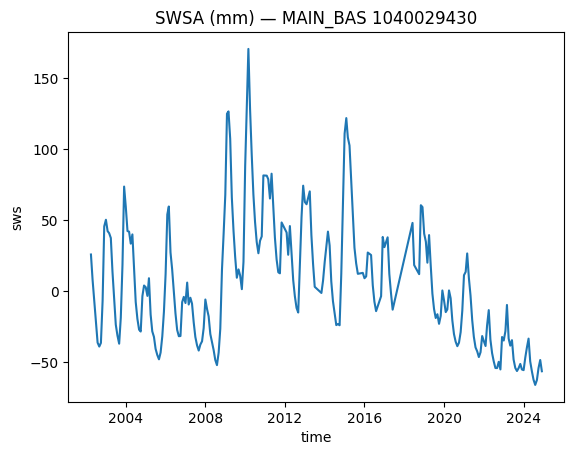

In [23]:
print("n basins:", len(main_ids_valid))

# pick the first basin with a valid TWS series (so plot won't fail)
bid = next(b for b in main_ids_valid if swsa_by_basin.get(b) is not None)

swe_ts = swe_by_basin.get(bid)
eto_ts = eto_by_basin.get(bid)
swsa_ts = swsa_by_basin.get(bid)

print("MAIN_BAS:", bid)
print("SWE is None?", swe_ts is None)
print("ETo is None?", eto_ts is None)
print("SWSA is None?", swsa_ts is None)

print("SWSA first 12 values:", swsa_ts.values[:12])
print("SWSA time range:", str(swsa_ts.time.min().values)[:10], "to", str(swsa_ts.time.max().values)[:10])

swsa_ts.plot()
plt.title(f"SWSA (mm) — MAIN_BAS {bid}")
plt.show()

In [24]:
def water_year(time):
    """
    Assign water year as Oct–Sep.
    """
    year = time.dt.year
    month = time.dt.month
    return xr.where(month >= 10, year + 1, year)

In [25]:
swe_peak_by_basin = {}
eto_summer_by_basin = {}

for bid in main_ids_valid:
    swe_ts = swe_by_basin.get(bid)
    eto_ts = eto_by_basin.get(bid)

    if (swe_ts is None) or (eto_ts is None):
        continue

    swe_ts = swe_ts.assign_coords(wy=water_year(swe_ts.time))
    eto_ts = eto_ts.assign_coords(wy=water_year(eto_ts.time))

    # peak SWE per WY (Dec–Mar)
    is_winter = swe_ts.time.dt.month.isin([12, 1, 2, 3])
    swe_peak = swe_ts.where(is_winter, drop=True).groupby("wy").max("time")

    # summer mean ETo per WY (Apr–Sep)
    is_summer = eto_ts.time.dt.month.isin([4, 5, 6, 7, 8, 9])
    eto_summer = eto_ts.where(is_summer, drop=True).groupby("wy").mean("time")

    swe_peak_by_basin[bid] = swe_peak
    eto_summer_by_basin[bid] = eto_summer

# quick sanity check on one basin that actually exists in the outputs
test_bid = next(b for b in main_ids_valid if b in swe_peak_by_basin)
print("Test basin:", test_bid)
print("SWE peak WY:", swe_peak_by_basin[test_bid])
print("ETo summer WY:", eto_summer_by_basin[test_bid])

Test basin: 1040029430
SWE peak WY: <xarray.DataArray 'swe' (wy: 23)> Size: 184B
array([ 9.13273926, 11.73994559,  6.54778819, 36.90673335, 17.11201848,
       19.97851793, 47.02822666,  8.14976564,  3.95172329,  7.03005888,
        6.67094642,  8.59633466, 24.15768049, 10.58910884,  6.17384717,
       42.03332532,  0.93076028,  3.22307711,  6.27637437,  2.09974908,
        7.07124089,  1.12682541,  0.75906972])
Coordinates:
  * wy       (wy) int64 184B 2003 2004 2005 2006 2007 ... 2022 2023 2024 2025
    region   int64 8B 75
    abbrevs  <U10 40B '1040029430'
    names    <U16 64B 'basin_1040029430'
ETo summer WY: <xarray.DataArray 'eto' (wy: 23)> Size: 184B
array([150.44709948, 158.73291198, 150.7224098 , 163.80722281,
       156.90822256, 155.70562658, 161.6616336 , 159.56606789,
       157.54069111, 155.92876978, 165.02811038, 160.83502622,
       163.04402837, 159.24077115, 163.12125324, 177.2298946 ,
       147.78738155, 165.33600589, 168.33737812, 165.50389557,
       168.797500

In [26]:
q_lo, q_hi = 0.30, 0.70
class_by_basin = {}

for bid in main_ids_valid:
    swe_peak = swe_peak_by_basin.get(bid)
    eto_summer = eto_summer_by_basin.get(bid)

    if (swe_peak is None) or (eto_summer is None):
        continue

    common_wy = np.intersect1d(swe_peak.wy.values, eto_summer.wy.values)
    if len(common_wy) == 0:
        continue

    swe_b = swe_peak.sel(wy=common_wy)
    eto_b = eto_summer.sel(wy=common_wy)

    # drop NaN years (important)
    valid = np.isfinite(swe_b.values) & np.isfinite(eto_b.values)
    swe_b = swe_b.isel(wy=valid)
    eto_b = eto_b.isel(wy=valid)
    if swe_b.sizes["wy"] == 0:
        continue

    common_wy = swe_b.wy.values.astype(int)

    swe_tlow  = float(swe_b.quantile(q_lo, dim="wy"))
    eto_thigh = float(eto_b.quantile(q_hi, dim="wy"))

    low_swe  = swe_b <= swe_tlow
    high_eto = eto_b >= eto_thigh

    df_class = pd.DataFrame({
        "WY": common_wy,
        "low_swe": low_swe.values,
        "high_eto": high_eto.values,
        "normal": (~low_swe & ~high_eto).values,
        "low_swe_only": (low_swe & ~high_eto).values,
        "high_eto_only": (~low_swe & high_eto).values,
        "low_swe_high_eto": (low_swe & high_eto).values,
    })

    class_by_basin[bid] = df_class

test_bid = next(iter(class_by_basin.keys()))
print("Example basin:", test_bid)
print(class_by_basin[test_bid].head())

Example basin: 1040029430
     WY  low_swe  high_eto  normal  low_swe_only  high_eto_only  \
0  2003    False     False    True         False          False   
1  2004    False     False    True         False          False   
2  2005    False     False    True         False          False   
3  2006    False     False    True         False          False   
4  2007    False     False    True         False          False   

   low_swe_high_eto  
0             False  
1             False  
2             False  
3             False  
4             False  


In [27]:
# print classification summary for a given basin ---

def print_basin_summary(bid):
    df = class_by_basin.get(bid)
    if df is None:
        print(f"No classification for basin {bid}")
        return

    print(f"\n=== Basin {bid} — Year Classification Summary ===\n")
    print(df.head())

    print("\nnormal:",              df.loc[df["normal"], "WY"].values)
    print("low swe:",               df.loc[df["low_swe"], "WY"].values)
    print("high eto:",              df.loc[df["high_eto"], "WY"].values)
    print("low swe only:",          df.loc[df["low_swe_only"], "WY"].values)
    print("high eto only:",         df.loc[df["high_eto_only"], "WY"].values)
    print("low swe AND high eto:",  df.loc[df["low_swe_high_eto"], "WY"].values)

    # optional sanity checks
    print("\nCounts:")
    print(df[["normal", "low_swe_only", "high_eto_only", "low_swe_high_eto"]].sum())

    n = len(df)
    ok = int(
        df["normal"].sum()
        + df["low_swe_only"].sum()
        + df["high_eto_only"].sum()
        + df["low_swe_high_eto"].sum()
    ) == n
    print("Total years:", n)
    print("Partition check:", ok)

# run on one example basin
test_bid = next(iter(class_by_basin.keys()))
print_basin_summary(test_bid)


=== Basin 1040029430 — Year Classification Summary ===

     WY  low_swe  high_eto  normal  low_swe_only  high_eto_only  \
0  2003    False     False    True         False          False   
1  2004    False     False    True         False          False   
2  2005    False     False    True         False          False   
3  2006    False     False    True         False          False   
4  2007    False     False    True         False          False   

   low_swe_high_eto  
0             False  
1             False  
2             False  
3             False  
4             False  

normal: [2003 2004 2005 2006 2007 2008 2009 2010 2012 2013 2014 2015 2016 2018]
low swe: [2011 2017 2019 2020 2021 2022 2024]
high eto: [2017 2019 2020 2021 2022 2023 2024]
low swe only: [2011]
high eto only: [2023]
low swe AND high eto: [2017 2019 2020 2021 2022 2024]

Counts:
normal              14
low_swe_only         1
high_eto_only        1
low_swe_high_eto     6
dtype: int64
Total years: 22
Partiti

In [28]:
# deseasonalize + detrend GRACE TWS for each basin

swsa_ds_by_basin = {}   # deseasonalized only
swsa_dt_by_basin = {}   # deseasonalized + detrended

for bid in main_ids_valid:
    swsa_ts = swsa_by_basin.get(bid)

    # skip basins with no soil water storage coverage
    if swsa_ts is None:
        continue

    # 1) remove mean monthly cycle 
    swsa_monclim = swsa_ts.groupby("time.month").mean("time")
    swsa_ds = swsa_ts.groupby("time.month") - swsa_monclim
    swsa_ds.name = "swsa_deseasonalized"

    # 2) fit linear trend and remove it
    lt = swsa_ds.polyfit(dim="time", deg=1, skipna=True)
    trend = xr.polyval(coord=swsa_ds["time"], coeffs=lt.polyfit_coefficients)

    swsa_dt = swsa_ds - trend
    swsa_dt.name = "swsa_deseasonalized_detrended"

    swsa_ds_by_basin[bid] = swsa_ds
    swsa_dt_by_basin[bid] = swsa_dt

# quick sanity check on one basin
test_bid = next(iter(swsa_dt_by_basin.keys()))
print("Test basin:", test_bid)
print(swsa_ds_by_basin[test_bid].isel(time=slice(0, 5)))
print(swsa_dt_by_basin[test_bid].isel(time=slice(0, 5)))

Test basin: 1040029430
<xarray.DataArray 'swsa_deseasonalized' (time: 5)> Size: 40B
array([ -3.01584122,  -2.45587754, -12.19015709, -12.24548012,
       -13.33185468])
Coordinates:
  * time     (time) datetime64[ns] 40B 2002-04-01 2002-05-01 ... 2002-10-01
    number   (time) int64 40B 0 0 0 0 0
    expver   (time) <U4 80B '0001' '0001' '0001' '0001' '0001'
    region   (time) int64 40B 75 75 75 75 75
    abbrevs  (time) <U10 200B '1040029430' '1040029430' ... '1040029430'
    names    (time) <U16 320B 'basin_1040029430' ... 'basin_1040029430'
    month    (time) int64 40B 4 5 8 9 10
<xarray.DataArray 'swsa_deseasonalized_detrended' (time: 5)> Size: 40B
array([-24.70020479, -23.98076211, -33.22597275, -33.11650081,
       -34.04339637])
Coordinates:
  * time     (time) datetime64[ns] 40B 2002-04-01 2002-05-01 ... 2002-10-01
    number   (time) int64 40B 0 0 0 0 0
    expver   (time) <U4 80B '0001' '0001' '0001' '0001' '0001'
    region   (time) int64 40B 75 75 75 75 75
    abbrevs  (t

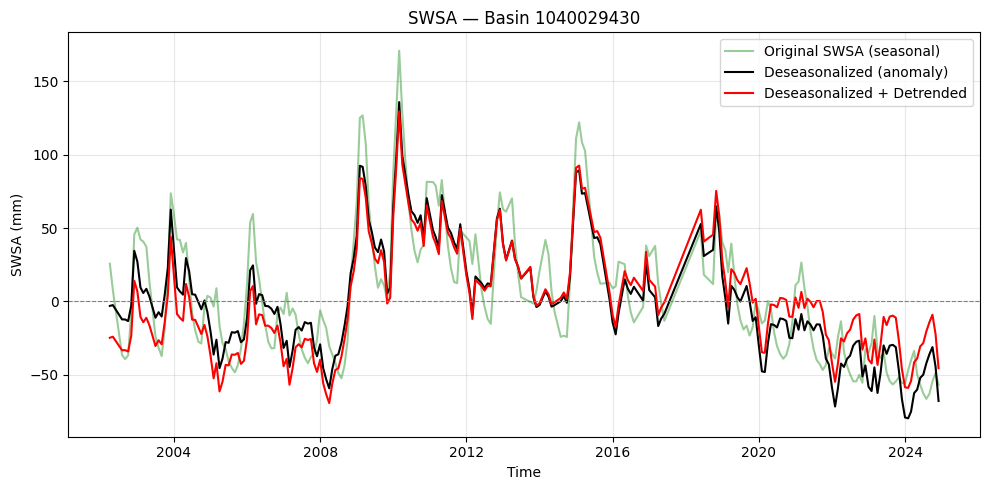

In [29]:
def plot_series_for_basin(bid):
    swsa_ts = swsa_by_basin.get(bid)
    swsa_ds = swsa_ds_by_basin.get(bid)
    swsa_dt = swsa_dt_by_basin.get(bid)

    if (swsa_ts is None) or (swsa_ds is None) or (swsa_dt is None):
        print(f"Missing series for basin {bid}")
        return

    plt.figure(figsize=(10, 5))

    # Original (seasonal)
    plt.plot(
        swsa_ts["time"], swsa_ts,
        label="Original SWSA (seasonal)",
        color="green", alpha=0.4
    )

    # Deseasonalized
    plt.plot(
        swsa_ds["time"], swsa_ds,
        label="Deseasonalized (anomaly)",
        color="black", linewidth=1.5
    )

    # Deseasonalized + detrended
    plt.plot(
        swsa_dt["time"], swsa_dt,
        label="Deseasonalized + Detrended",
        color="red", linewidth=1.5
    )

    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.xlabel("Time")
    plt.ylabel("SWSA (mm)")
    plt.title(f"SWSA — Basin {bid}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# try on one basin
test_bid = next(iter(swsa_ds_by_basin.keys()))
plot_series_for_basin(test_bid)

In [30]:
# interpolate small gaps (≤ 2 months) in GRACE for each basin ---

def interp_small_gaps(da, max_gap=2):
    """
    Interpolate only NaN runs of length ≤ max_gap along time.
    """
    isnan = da.isnull()
    groups = (~isnan).cumsum()               # label contiguous segments
    gap_sizes = isnan.groupby(groups).sum()  # count NaNs in each segment

    # groups that are "small" gaps
    small_gaps = gap_sizes.where(gap_sizes <= max_gap)
    small_gap_groups = (
        small_gaps.drop_vars(small_gaps.coords)
                  .to_series()
                  .dropna()
                  .index
    )

    allowed_mask = groups.isin(small_gap_groups)  # True where we allow interp

    # interpolate only on allowed positions
    da_interp = da.where(~allowed_mask).combine_first(
        da.interpolate_na(dim="time", method="linear")
    )
    return da_interp

swsa_ds_interp_by_basin = {}
swsa_dt_interp_by_basin = {}

for bid in main_ids_valid:
    swsa_ds = swsa_ds_by_basin.get(bid)
    swsa_dt = swsa_dt_by_basin.get(bid)
    if (swsa_ds is None) or (swsa_dt is None):
        continue

    swsa_ds_interp = interp_small_gaps(swsa_ds, max_gap=2)
    swsa_dt_interp = interp_small_gaps(swsa_dt, max_gap=2)

    swsa_ds_interp_by_basin[bid] = swsa_ds_interp
    swsa_dt_interp_by_basin[bid] = swsa_dt_interp

# quick check on one basin
test_bid = next(iter(swsa_ds_interp_by_basin.keys()))
print("Check interpolated deseasonalized series for basin:", test_bid)
print(swsa_ds_interp_by_basin[test_bid].isel(time=slice(0, 10)))

Check interpolated deseasonalized series for basin: 1040029430
<xarray.DataArray 'swsa_deseasonalized' (time: 10)> Size: 80B
array([ -3.01584122,  -2.45587754, -12.19015709, -12.24548012,
       -13.33185468,  -2.73306068,  34.50175969,  27.13571354,
         9.53008613,   5.80589429])
Coordinates:
  * time     (time) datetime64[ns] 80B 2002-04-01 2002-05-01 ... 2003-03-01
    number   (time) int64 80B 0 0 0 0 0 0 0 0 0 0
    expver   (time) <U4 160B '0001' '0001' '0001' ... '0001' '0001' '0001'
    region   (time) int64 80B 75 75 75 75 75 75 75 75 75 75
    abbrevs  (time) <U10 400B '1040029430' '1040029430' ... '1040029430'
    names    (time) <U16 640B 'basin_1040029430' ... 'basin_1040029430'
    month    (time) int64 80B 4 5 8 9 10 11 12 1 2 3


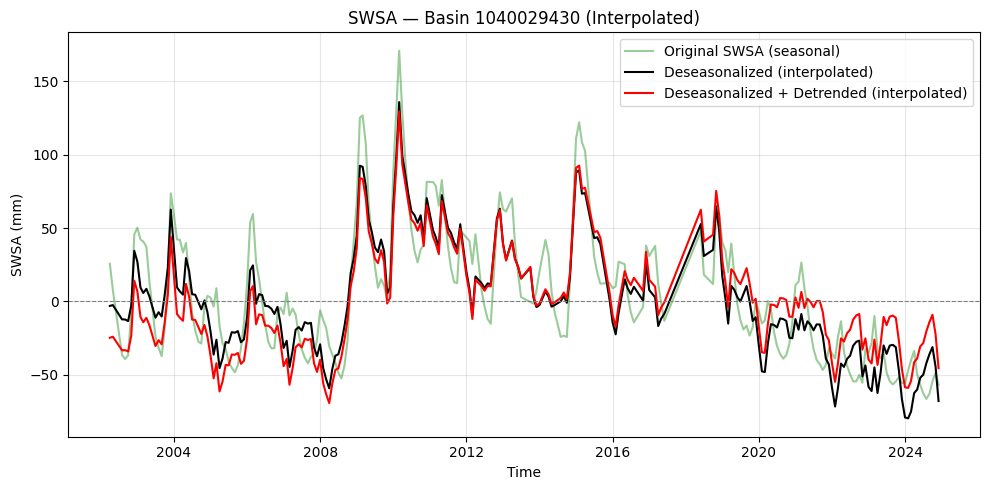

In [31]:
def plot_interpolated_for_basin(bid):
    swsa_ts  = swsa_by_basin.get(bid)
    swsa_ds_i = swsa_ds_interp_by_basin.get(bid)
    swsa_dt_i = swsa_dt_interp_by_basin.get(bid)

    if (swsa_ts is None) or (swsa_ds_i is None) or (swsa_dt_i is None):
        print(f"Missing data for basin {bid}")
        return

    plt.figure(figsize=(10, 5))

    # Original
    plt.plot(
        swsa_ts["time"], swsa_ts,
        label="Original SWSA (seasonal)",
        color="green", alpha=0.4
    )

    # Deseasonalized (interpolated)
    plt.plot(
        swsa_ds_i["time"], swsa_ds_i,
        label="Deseasonalized (interpolated)",
        color="black", linewidth=1.5
    )

    # Deseasonalized + detrended (interpolated)
    plt.plot(
        swsa_dt_i["time"], swsa_dt_i,
        label="Deseasonalized + Detrended (interpolated)",
        color="red", linewidth=1.5
    )

    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.xlabel("Time")
    plt.ylabel("SWSA (mm)")
    plt.title(f"SWSA — Basin {bid} (Interpolated)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# try it on a basin
test_bid = next(iter(swsa_dt_interp_by_basin.keys()))
plot_interpolated_for_basin(test_bid)

In [32]:
# # add water year + find valid GRACE WYs per basin

# rsa_dt_interp_wy_by_basin = {}
# valid_wy_by_basin = {}

# for bid in main_ids_valid:
#     rsa_dt_i = rsa_dt_interp_by_basin.get(bid)
#     if rsa_dt_i is None:
#         continue

#     # add water-year coord (Oct–Sep)
#     rsa_dt_i = rsa_dt_i.assign_coords(wy=water_year(rsa_dt_i.time))

#     valid_years = []
#     for wy in np.unique(rsa_dt_i.wy.values.astype(int)):
#         start = pd.Timestamp(wy - 1, 9, 1)
#         end   = pd.Timestamp(wy,     9, 30)
#         seg   = rsa_dt_i.sel(time=slice(start, end))

#         # require at least 7 months of GRACE in that WY
#         if seg.count() >= 7:
#             valid_years.append(int(wy))

#     rsa_dt_interp_wy_by_basin[bid] = rsa_dt_i
#     valid_wy_by_basin[bid] = valid_years

# # quick sanity check
# test_bid = next(iter(valid_wy_by_basin.keys()))
# print("Basin:", test_bid)
# print("Valid GRACE water years:", valid_wy_by_basin[test_bid])


In [33]:
# add water year + find valid WYs per basin

swsa_ds_interp_wy_by_basin = {}
valid_wy_by_basin = {}

for bid in main_ids_valid:
    swsa_ds_i = swsa_ds_interp_by_basin.get(bid)
    if swsa_ds_i is None:
        continue

    # add water-year coord (Oct–Sep)
    swsa_ds_i = swsa_ds_i.assign_coords(wy=water_year(swsa_ds_i.time))

    valid_years = []
    for wy in np.unique(swsa_ds_i.wy.values.astype(int)):
        start = pd.Timestamp(wy - 1, 9, 1)
        end   = pd.Timestamp(wy,     9, 30)
        seg   = swsa_ds_i.sel(time=slice(start, end))

        # require at least 7 months of GRACE in that WY
        if seg.count() >= 7:
            valid_years.append(int(wy))

    swsa_ds_interp_wy_by_basin[bid] = swsa_ds_i
    valid_wy_by_basin[bid] = valid_years

# quick sanity check
test_bid = next(iter(valid_wy_by_basin.keys()))
print("Basin:", test_bid)
print("Valid water years:", valid_wy_by_basin[test_bid])


Basin: 1040029430
Valid water years: [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2019, 2020, 2021, 2022, 2023, 2024]


In [34]:
# build year lists per class, per basin (only GRACE-valid WYs)

groups_by_basin = {}

for bid in main_ids_valid:
    df_class = class_by_basin.get(bid)
    valid_wy = valid_wy_by_basin.get(bid)

    if df_class is None or not valid_wy:
        continue

    wy_swsa = set(valid_wy)

    yrs_normal = sorted(set(df_class.loc[df_class["normal"], "WY"].astype(int)) & wy_swsa)
    yrs_low_swe = sorted(set(df_class.loc[df_class["low_swe"], "WY"].astype(int)) & wy_swsa)
    yrs_high_eto = sorted(set(df_class.loc[df_class["high_eto"], "WY"].astype(int)) & wy_swsa)
    yrs_low_swe_only = sorted(set(df_class.loc[df_class["low_swe_only"], "WY"].astype(int)) & wy_swsa)
    yrs_high_eto_only = sorted(set(df_class.loc[df_class["high_eto_only"], "WY"].astype(int)) & wy_swsa)
    yrs_low_swe_high_eto = sorted(set(df_class.loc[df_class["low_swe_high_eto"], "WY"].astype(int)) & wy_swsa)

    groups_by_basin[bid] = {
        "normal": yrs_normal,
        "low_swe": yrs_low_swe,
        "high_eto": yrs_high_eto,
        "low_swe_only": yrs_low_swe_only,
        "high_eto_only": yrs_high_eto_only,
        "low_swe_high_eto": yrs_low_swe_high_eto,
    }

# quick sanity check
test_bid = next(iter(groups_by_basin.keys()))
print("Basin:", test_bid)
for k, v in groups_by_basin[test_bid].items():
    print(k, ":", v)

Basin: 1040029430
normal : [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2012, 2013, 2014, 2015, 2016]
low_swe : [2011, 2017, 2019, 2020, 2021, 2022, 2024]
high_eto : [2017, 2019, 2020, 2021, 2022, 2023, 2024]
low_swe_only : [2011]
high_eto_only : [2023]
low_swe_high_eto : [2017, 2019, 2020, 2021, 2022, 2024]


In [35]:
# # build Sept→Sept GRACE trajectories & ΔTWS per basin and class ---

# traj_by_basin = {}   # {bid: {group_name: 2D array (n_years, 13)}}
# comp_by_basin = {}   # {bid: {group_name: 1D array (13,)}}
# delta_by_basin = {}  # {bid: {group_name: float}}

# x = np.arange(13)  # 0..12 months from Sept(start)

# for bid in groups_by_basin.keys():
#     rsa_dt_i = rsa_dt_interp_wy_by_basin.get(bid)
#     if rsa_dt_i is None:
#         continue

#     groups = groups_by_basin[bid]
#     traj_by_group = {}
#     comp_by_group = {}
#     delta_by_group = {}

#     for name, years in groups.items():
#         curves = []
#         kept_years = []

#         for wy in years:
#             start = pd.Timestamp(wy - 1, 9, 1)
#             end   = pd.Timestamp(wy,     9, 30)

#             seg = rsa_dt_i.sel(time=slice(start, end)).resample(time="MS").mean()
#             ms  = (seg.time.dt.year - start.year) * 12 + (seg.time.dt.month - start.month)

#             y = np.full(13, np.nan)
#             for m, val in zip(ms.values, seg.values):
#                 if 0 <= m <= 12:
#                     y[int(m)] = val

#             # skip this WY if starting Sept is missing
#             if not np.isfinite(y[0]):
#                 continue

#             # normalize so Sept(start) = 0
#             y = y - y[0]

#             curves.append(y)
#             kept_years.append(int(wy))

#         if curves:
#             stack = np.vstack(curves)  # (n_years, 13)
#             col_has_data = np.isfinite(stack).any(axis=0)

#             comp = np.full(13, np.nan)
#             if col_has_data.any():
#                 comp[col_has_data] = np.nanmean(stack[:, col_has_data], axis=0)

#             delta = float(comp[12]) if np.isfinite(comp[12]) else np.nan

#             traj_by_group[name]  = stack
#             comp_by_group[name]  = comp
#             delta_by_group[name] = delta

#             # update to only years actually used
#             groups[name] = kept_years

#     traj_by_basin[bid]  = traj_by_group
#     comp_by_basin[bid]  = comp_by_group
#     delta_by_basin[bid] = delta_by_group
#     groups_by_basin[bid] = groups  # overwrite with kept years

# # quick sanity check
# test_bid = next(iter(delta_by_basin.keys()))
# print("Basin:", test_bid)
# print("ΔRSA (Sep→Sep) [mm] by group:", delta_by_basin[test_bid])

In [36]:
# build Sept→Sept SWSA trajectories per basin and class ---

traj_by_basin = {}   # {bid: {group_name: 2D array (n_years, 13)}}
comp_by_basin = {}   # {bid: {group_name: 1D array (13,)}}
delta_by_basin = {}  # {bid: {group_name: float}}

x = np.arange(13)  # 0..12 months from Sept(start)

for bid in groups_by_basin.keys():
    swsa_ds_i = swsa_ds_interp_wy_by_basin.get(bid)
    if swsa_ds_i is None:
        continue

    groups = groups_by_basin[bid]
    traj_by_group = {}
    comp_by_group = {}
    delta_by_group = {}

    for name, years in groups.items():
        curves = []
        kept_years = []

        for wy in years:
            start = pd.Timestamp(wy - 1, 9, 1)
            end   = pd.Timestamp(wy,     9, 30)

            seg = swsa_ds_i.sel(time=slice(start, end)).resample(time="MS").mean()
            ms  = (seg.time.dt.year - start.year) * 12 + (seg.time.dt.month - start.month)

            y = np.full(13, np.nan)
            for m, val in zip(ms.values, seg.values):
                if 0 <= m <= 12:
                    y[int(m)] = val

            # skip this WY if either September endpoint is missing
            if not (np.isfinite(y[0]) and np.isfinite(y[12])):
                continue

            # normalize so Sept(start) = 0
            y = y - y[0]

            curves.append(y)
            kept_years.append(int(wy))

        if curves:
            stack = np.vstack(curves)  # (n_years, 13)
            col_has_data = np.isfinite(stack).any(axis=0)

            comp = np.full(13, np.nan)
            if col_has_data.any():
                comp[col_has_data] = np.nanmean(stack[:, col_has_data], axis=0)

            delta = float(comp[12]) if np.isfinite(comp[12]) else np.nan

            traj_by_group[name]  = stack
            comp_by_group[name]  = comp
            delta_by_group[name] = delta

            # update to only years actually used
            groups[name] = kept_years

    traj_by_basin[bid]  = traj_by_group
    comp_by_basin[bid]  = comp_by_group
    delta_by_basin[bid] = delta_by_group
    groups_by_basin[bid] = groups  # overwrite with kept years

# quick sanity check
test_bid = next(iter(delta_by_basin.keys()))
print("Basin:", test_bid)
print("ΔSWSA (Sep→Sep) [mm] by group:", delta_by_basin[test_bid])

Basin: 1040029430
ΔSWSA (Sep→Sep) [mm] by group: {'normal': 7.276046429028781, 'low_swe': -11.547705898749514, 'high_eto': -9.283887593798019, 'low_swe_only': -13.40350165822592, 'high_eto_only': -2.0844101334684453, 'low_swe_high_eto': -11.083756958880413}


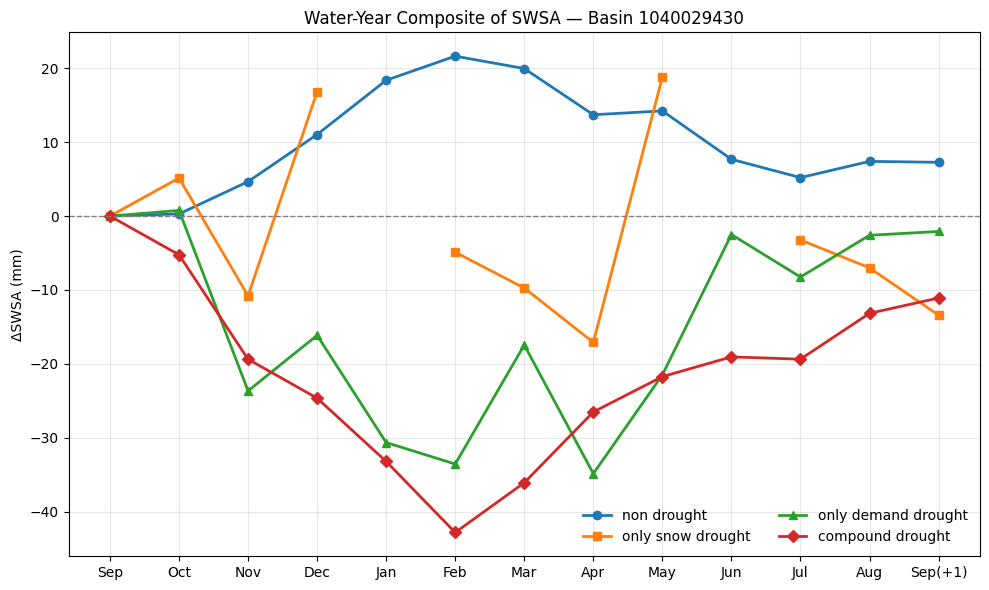

In [37]:
def plot_composite_for_basin(bid):
    """
    Line plot of Sept→Sept SWSA composites for one basin,
    using comp_by_basin[bid] (the per-group 13-month curves).
    """
    if bid not in comp_by_basin:
        print(f"No composites found for basin {bid}")
        return

    comp_by_group = comp_by_basin[bid]

    x = np.arange(13)
    month_labels = [
        "Sep","Oct","Nov","Dec","Jan","Feb","Mar",
        "Apr","May","Jun","Jul","Aug","Sep(+1)"
    ]

    order = [
        "normal",
        "low_swe_only",
        "high_eto_only",
        "low_swe_high_eto",
    ]
    display = {
        "normal": "non drought",
        "low_swe_only": "only snow drought",
        "high_eto_only": "only demand drought",
        "low_swe_high_eto": "compound drought"
    }
    markers = ["o","s","^","D","v","P"]

    fig, ax = plt.subplots(figsize=(10,6))
    line_colors = {}

    for i, name in enumerate(order):
        if name not in comp_by_group:
            continue
        y = comp_by_group[name]
        if y is None:
            continue

        line, = ax.plot(
            x, y,
            marker=markers[i % len(markers)],
            linewidth=2,
            label=display[name]
        )
        line_colors[name] = line.get_color()

    ax.axhline(0, linewidth=1, linestyle="--", color="gray")
    ax.set_xticks(x)
    ax.set_xticklabels(month_labels)
    ax.set_ylabel("ΔSWSA (mm)")
    ax.set_title(f"Water-Year Composite of SWSA — Basin {bid}")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()

# example: pick any basin with composites
test_bid = next(iter(comp_by_basin.keys()))
plot_composite_for_basin(test_bid)


In [38]:
bid = 7030008720

if bid not in comp_by_basin:
    print("No GRACE composites for this basin.")
else:
    plot_composite_for_basin(bid)

No GRACE composites for this basin.


EPSG:4326
Original basins: 1342
Basins intersecting 0–60°N: 846


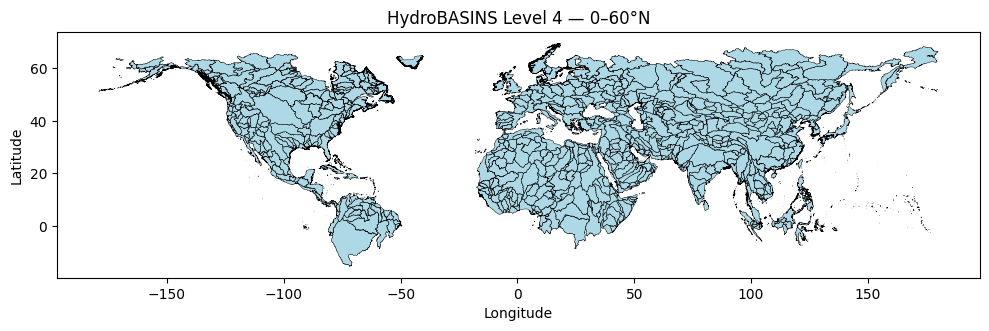

In [39]:
from shapely.geometry import box

# Read HydroBASINS level 3
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")
print(hb.crs)

# Define bounding box for 0–60°N (all longitudes)
bbox_geom = box(-180, 0, 180, 60)  # (minx, miny, maxx, maxy)

# Keep polygons that intersect this band (including edge-touching basins)
hb_0_60N = hb[hb.geometry.intersects(bbox_geom)].copy()

print("Original basins:", len(hb))
print("Basins intersecting 0–60°N:", len(hb_0_60N))

# Quick plot
fig, ax = plt.subplots(figsize=(10, 6))
hb_0_60N.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4 — 0–60°N")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [40]:
hb_simple = hb_0_60N.copy()
hb_simple["geometry"] = hb_0_60N.geometry.simplify(0.01, preserve_topology=True)

# Fix invalid geometries introduced by simplify
hb_simple["geometry"] = hb_simple.geometry.buffer(0)

# Get ALL MAIN_BAS IDs (sorted)
main_ids = np.sort(hb_simple["MAIN_BAS"].unique())

In [41]:
# store results as: results[bid]['comp_vs_normal'] = {...}
ttest_results = {}

for bid, traj_groups in traj_by_basin.items():
    basin_res = {}

    def get_delta(group_name):
        """Return 1D array of ΔSWSA (mm) for each WY in this group."""
        if group_name not in traj_groups:
            return None
        stack = traj_groups[group_name]          # shape (n_years, 13)
        d = stack[:, 12]                         # Sept→Sept change
        d = d[np.isfinite(d)]                    # drop NaNs
        return d

    d_comp   = get_delta("low_swe_high_eto")
    d_norm   = get_delta("normal")
    d_low    = get_delta("low_swe_only")
    d_high   = get_delta("high_eto_only")

    # helper for one comparison
    def add_test(key, a, b):
        if a is None or b is None:
            return
        if (len(a) < 2) or (len(b) < 2):
            return  # too few years for a meaningful t-test
        tstat, pval = ttest_ind(a, b, equal_var=False, nan_policy="omit")
        basin_res[key] = {
            "mean_diff": float(np.nanmean(a) - np.nanmean(b)),  # groupA - groupB
            "p_value": float(pval),
            "n_A": int(len(a)),
            "n_B": int(len(b)),
        }

    # Compound vs non-drought
    add_test("comp_vs_normal", d_comp, d_norm)

    # Compound vs low SWE only
    add_test("comp_vs_low_swe_only", d_comp, d_low)

    # Compound vs high ETo only
    add_test("comp_vs_high_eto_only", d_comp, d_high)

    if basin_res:
        ttest_results[bid] = basin_res

# quick peek at one basin
some_bid = next(iter(ttest_results.keys()))
print("Basin:", some_bid)
print(ttest_results[some_bid])

Basin: 1040029430
{'comp_vs_normal': {'mean_diff': -18.359803387909196, 'p_value': 0.06872481580909347, 'n_A': 4, 'n_B': 10}}


In [42]:
# Build ΔTWS differences per basin

delta_comp_norm_by_basin     = {}
delta_comp_lowonly_by_basin  = {}
delta_comp_highonly_by_basin = {}

for bid, dct in delta_by_basin.items():
    d_comp    = dct.get("low_swe_high_eto", np.nan)
    d_normal  = dct.get("normal", np.nan)
    d_lowonly = dct.get("low_swe_only", np.nan)
    d_highonly = dct.get("high_eto_only", np.nan)

    # Compound vs non-drought
    if np.isfinite(d_comp) and np.isfinite(d_normal):
        delta_comp_norm_by_basin[bid] = d_comp - d_normal
    else:
        delta_comp_norm_by_basin[bid] = np.nan

    # Compound vs low SWE only
    if np.isfinite(d_comp) and np.isfinite(d_lowonly):
        delta_comp_lowonly_by_basin[bid] = d_comp - d_lowonly
    else:
        delta_comp_lowonly_by_basin[bid] = np.nan

    # Compound vs high ETo only
    if np.isfinite(d_comp) and np.isfinite(d_highonly):
        delta_comp_highonly_by_basin[bid] = d_comp - d_highonly
    else:
        delta_comp_highonly_by_basin[bid] = np.nan

In [43]:
# One geometry per MAIN_BAS + attach all three fields

basins_diss = hb_simple.dissolve(by="MAIN_BAS").reset_index()

basins_diss["dSWSA_comp_minus_norm"]     = basins_diss["MAIN_BAS"].map(delta_comp_norm_by_basin)
basins_diss["dSWSA_comp_minus_lowonly"]  = basins_diss["MAIN_BAS"].map(delta_comp_lowonly_by_basin)
basins_diss["dSWSA_comp_minus_highonly"] = basins_diss["MAIN_BAS"].map(delta_comp_highonly_by_basin)

In [44]:
p_comp_norm_by_basin     = {}
p_comp_lowonly_by_basin  = {}
p_comp_highonly_by_basin = {}

for bid in basins_diss["MAIN_BAS"].values:
    res = ttest_results.get(bid, {})

    # Compound vs non-drought
    if "comp_vs_normal" in res:
        p_comp_norm_by_basin[bid] = res["comp_vs_normal"]["p_value"]
    else:
        p_comp_norm_by_basin[bid] = np.nan

    # Compound vs low SWE only
    if "comp_vs_low_swe_only" in res:
        p_comp_lowonly_by_basin[bid] = res["comp_vs_low_swe_only"]["p_value"]
    else:
        p_comp_lowonly_by_basin[bid] = np.nan

    # Compound vs high ETo only
    if "comp_vs_high_eto_only" in res:
        p_comp_highonly_by_basin[bid] = res["comp_vs_high_eto_only"]["p_value"]
    else:
        p_comp_highonly_by_basin[bid] = np.nan

In [45]:
def plot_global_delta(column, title, p_dict=None, alpha=0.05):
    valid = basins_diss[basins_diss[column].notna()]
    if valid.empty:
        print(f"No data to plot for {column}")
        return

    # Fixed limits
    vmin, vmax = -120, 120
    bounds = np.arange(vmin, vmax + 20, 20)
    n_bins = len(bounds) - 1

    base_cmap = plt.get_cmap("RdBu", n_bins)
    colors = base_cmap(np.linspace(0, 1, n_bins))

    # make -20..0 and 0..20 white
    colors[5] = [1, 1, 1, 1]
    colors[6] = [1, 1, 1, 1]

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

    # Create figure/axis in a consistent way
    fig, ax = plt.subplots(
        figsize=(12, 6),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

    ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

    # First reserve layout space
    fig.subplots_adjust(top=0.90, bottom=0.16, left=0.02, right=0.98)

    # Then place identical colorbar axis in figure coordinates
    cax = fig.add_axes([0.15, 0.14, 0.70, 0.03])

    basins_diss.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.2,
        legend=True,
        cax=cax,
        transform=ccrs.PlateCarree(),
        legend_kwds={
            "orientation": "horizontal",
            "label": "ΔSWSA (mm)",
            "ticks": bounds
        },
        missing_kwds={
            "color": "lightgray",
            "edgecolor": "black",
            "label": "Insufficient data"
        },
    )

    if p_dict is not None:
        sig_ids = [
            bid for bid, p in p_dict.items()
            if (p is not None) and np.isfinite(p) and (p < alpha)
        ]

        print(f"{len(sig_ids)} significant basins (p < {alpha}) for {title}")

        sig_gdf = basins_diss[basins_diss["MAIN_BAS"].isin(sig_ids)]

        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=ax,
                facecolor="none",
                edgecolor="black",
                linewidth=0.4,
                hatch="///",
                transform=ccrs.PlateCarree()
            )

            hatch_patch = mpatches.Patch(
                facecolor="none",
                edgecolor="black",
                hatch="///",
                label="p < 0.05"
            )
            ax.legend(
                handles=[hatch_patch],
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=False
            )

    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.show()

In [46]:
# def plot_global_delta(column, title, p_dict=None, alpha=0.05):
#     valid = basins_diss[basins_diss[column].notna()]
#     if valid.empty:
#         print(f"No data to plot for {column}")
#         return

#     # Fixed limits
#     vmin, vmax = -120, 120

#     # 20-mm discrete bins
#     bounds = np.arange(vmin, vmax + 20, 20)  # [-120, -100, ..., 100, 120]
#     n_bins = len(bounds) - 1

#     # Build discrete RdBu first
#     base_cmap = plt.get_cmap("RdBu", n_bins)
#     colors = base_cmap(np.linspace(0, 1, n_bins))

#     # make -20..0 and 0..20 white
#     colors[5] = [1, 1, 1, 1]
#     colors[6] = [1, 1, 1, 1]

#     cmap = mcolors.ListedColormap(colors)
#     norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

#     # --- Cartopy axis ---
#     fig = plt.figure(figsize=(12,6))
#     ax = plt.axes(projection=ccrs.PlateCarree())
#     ax.set_extent([-180, 180, 0, 75], crs=ccrs.PlateCarree()) 


#     # --- Add country boundaries + coastlines ---
#     ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
#     ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
#     cax = fig.add_axes([0.10, 0.06, 0.80, 0.035])


#     # base colored map

#     basins_diss.plot(
#     ax=ax,
#     column=column,
#     cmap=cmap,
#     norm=norm,
#     edgecolor="black",
#     linewidth=0.2,
#     legend=True,
#     cax=cax,   # <-- forces identical colorbar placement/size
#     legend_kwds={
#         "orientation": "horizontal",
#         "label": "ΔSWSA (mm)",
#         "ticks": bounds
#     },
#     missing_kwds={
#         "color": "lightgray",
#         "edgecolor": "black",
#         "label": "Insufficient data"
#     },
#     )

#     # overlay hatching where p < alpha
#     if p_dict is not None:
#         sig_ids = [
#             bid for bid, p in p_dict.items()
#             if (p is not None) and np.isfinite(p) and (p < alpha)
#         ]

#         # helpful to sanity check
#         print(f"{len(sig_ids)} significant basins (p < {alpha}) for {title}")

#         sig_gdf = basins_diss[basins_diss["MAIN_BAS"].isin(sig_ids)]

#         if not sig_gdf.empty:
#             sig_gdf.plot(
#                 ax=ax,
#                 facecolor="none",
#                 edgecolor="black",
#                 linewidth=0.4,
#                 hatch="///"
#             )

#             # simple legend entry for significance
#             hatch_patch = mpatches.Patch(
#                 facecolor="none",
#                 edgecolor="black",
#                 hatch="///",
#                 label="p < 0.05"
#             )
#             ax.legend(handles=[hatch_patch], loc="lower left", bbox_to_anchor=(0.02, 0.02), frameon=False)

#     ax.set_title(title, fontsize=14, pad=10)
#     ax.set_xticks([])
#     ax.set_xticklabels([])
#     ax.set_ylabel("Latitude")
#     plt.subplots_adjust(top=0.92, bottom=-0.08, left=0.02, right=0.98)
#     plt.show()

# # Basins are greyed out because:
# # 1. It did not have ≥ 7 valid GRACE months in a WY 
# # 2. it has too many gaps (>2 months and cannot be interpolated)
# # 3. If the September end points are missing → WY is discarded.
# # 4. SWE/ETo classification produced no years in the class or basin never had that event type

31 significant basins (p < 0.05) for ΔSWSA (Sep→Sep): Compound − Non-drought


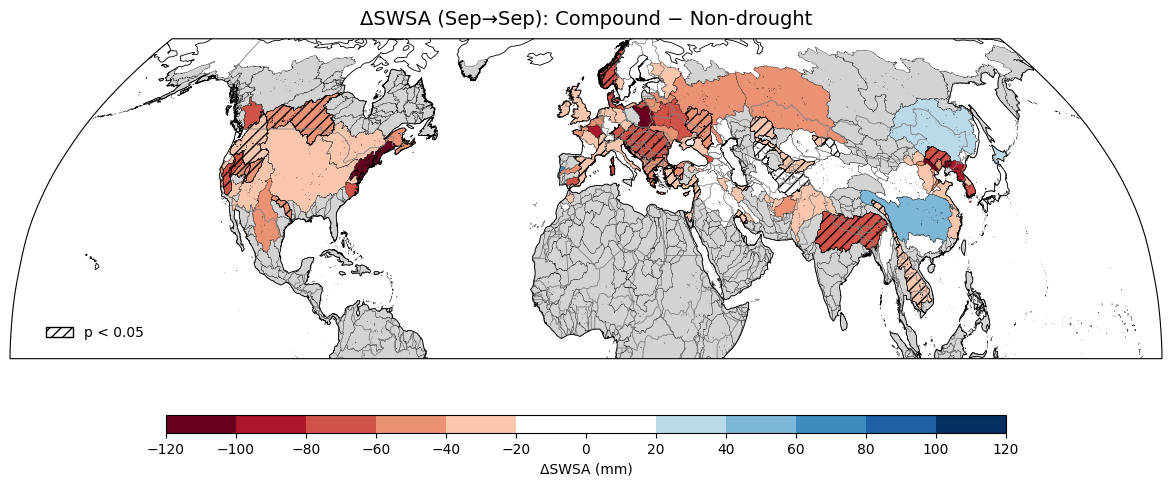

In [47]:
plot_global_delta(
    "dSWSA_comp_minus_norm",
    "ΔSWSA (Sep→Sep): Compound − Non-drought",
    p_dict=p_comp_norm_by_basin,
    alpha=0.05
)

10 significant basins (p < 0.05) for ΔSWSA (Sep→Sep): Compound − snow drought only


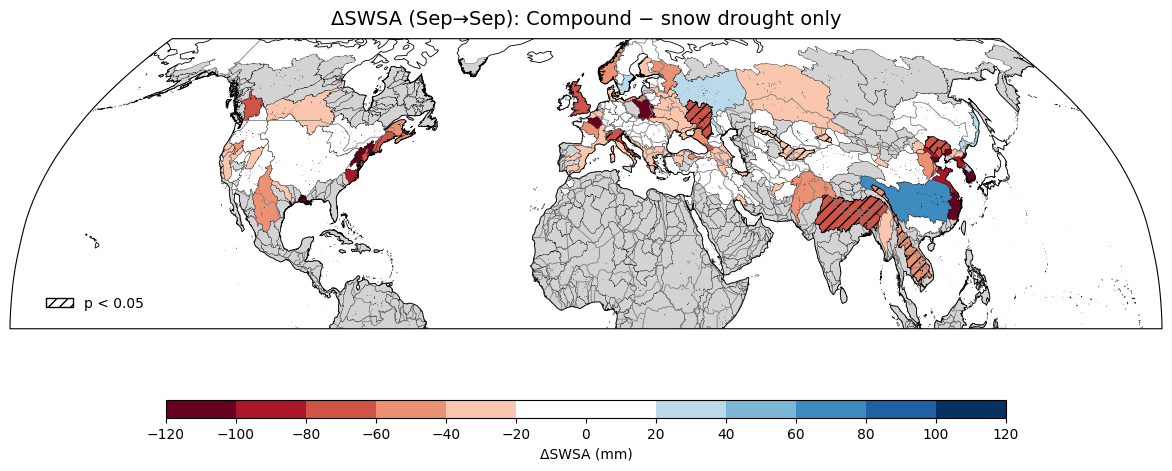

In [48]:
plot_global_delta(
    "dSWSA_comp_minus_lowonly",
    "ΔSWSA (Sep→Sep): Compound − snow drought only",
    p_dict=p_comp_lowonly_by_basin,
    alpha=0.05
)

6 significant basins (p < 0.05) for ΔSWSA (Sep→Sep): Compound − demand drought only


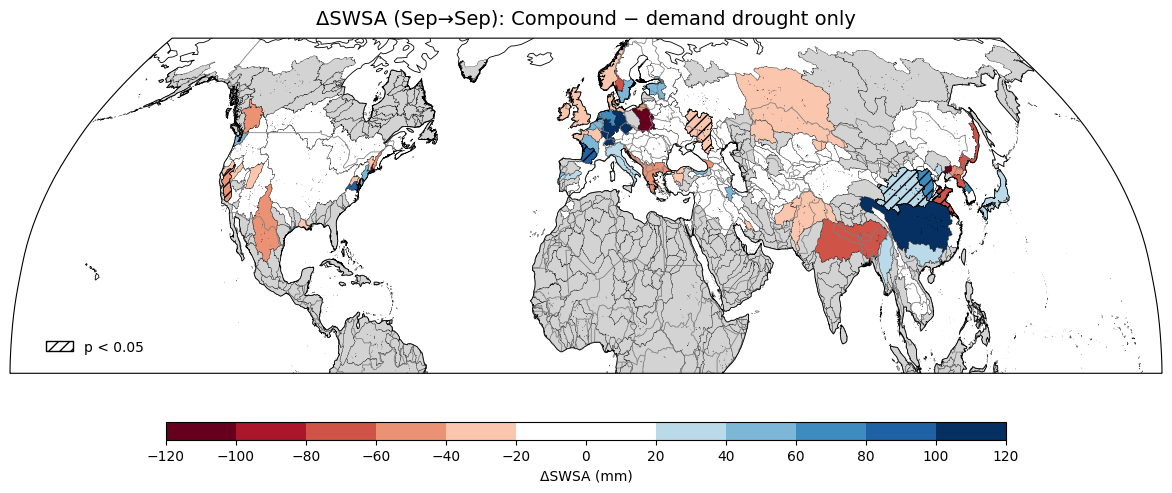

In [49]:
plot_global_delta(
    "dSWSA_comp_minus_highonly",
    "ΔSWSA (Sep→Sep): Compound − demand drought only",
    p_dict=p_comp_highonly_by_basin,
    alpha=0.05
)

(d) ΔSM (Sep→Sep): Compound − No-drought
{'n_valid': 155, 'n_sig': 31, 'n_inc': 0, 'n_dec': 31, 'pct_inc': 0.0, 'pct_dec': 20.0}
(e) ΔSM (Sep→Sep): Compound − Snow drought only
{'n_valid': 157, 'n_sig': 10, 'n_inc': 0, 'n_dec': 10, 'pct_inc': 0.0, 'pct_dec': 6.369426751592357}
(f) ΔSM (Sep→Sep): Compound − Demand drought only
{'n_valid': 153, 'n_sig': 6, 'n_inc': 3, 'n_dec': 3, 'pct_inc': 1.9607843137254901, 'pct_dec': 1.9607843137254901}
Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_5.png


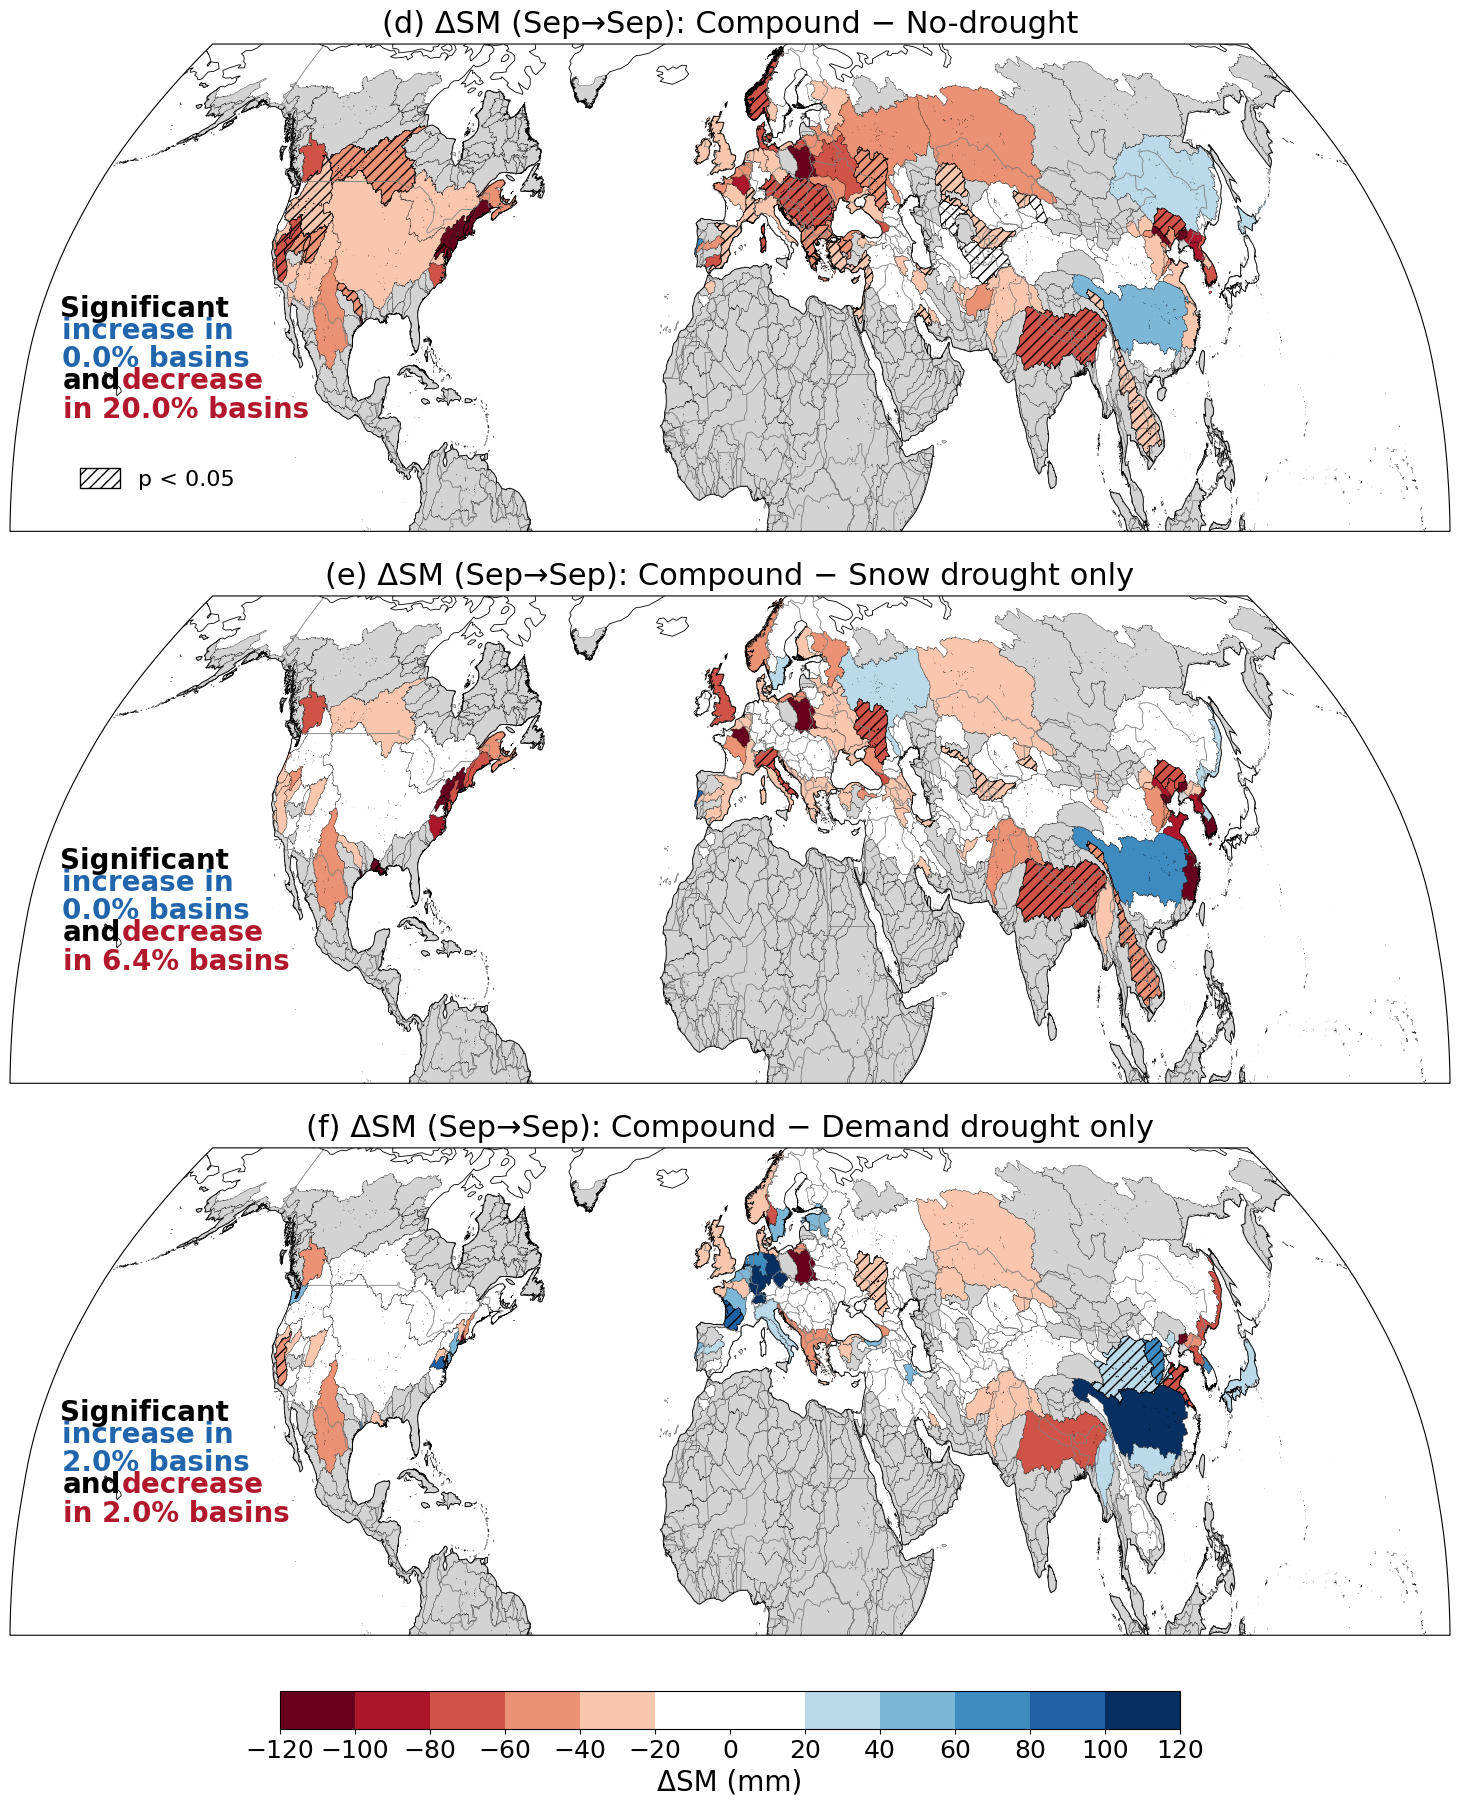

In [55]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


# ------------------------------------------------------------
# Helper: count significant positive / negative basins
# Percentages are relative to basins with non-missing values
# for the plotted column.
# ------------------------------------------------------------
def get_sig_stats(gdf, column, p_dict, alpha=0.05):
    pvals = gdf["MAIN_BAS"].map(p_dict)

    valid = gdf[column].notna()
    sig = valid & pvals.notna() & (pvals < alpha)

    sig_inc = sig & (gdf[column] > 0)
    sig_dec = sig & (gdf[column] < 0)

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_inc = int(sig_inc.sum())
    n_dec = int(sig_dec.sum())

    pct_inc = 100 * n_inc / n_valid if n_valid > 0 else np.nan
    pct_dec = 100 * n_dec / n_valid if n_valid > 0 else np.nan

    return {
        "n_valid": n_valid,
        "n_sig": n_sig,
        "n_inc": n_inc,
        "n_dec": n_dec,
        "pct_inc": pct_inc,
        "pct_dec": pct_dec,
    }


# ------------------------------------------------------------
# Panel plotting function
# ------------------------------------------------------------
def plot_global_delta_panels_vertical(
    gdf,
    outname="Fig_5.png",
    alpha=0.05
):
    # --------------------------------------------------------
    # Panel definitions
    # --------------------------------------------------------
    panel_info = [
        {
            "column": "dSWSA_comp_minus_norm",
            "title": "(d) ΔSM (Sep→Sep): Compound − No-drought",
            "p_dict": p_comp_norm_by_basin,
        },
        {
            "column": "dSWSA_comp_minus_lowonly",
            "title": "(e) ΔSM (Sep→Sep): Compound − Snow drought only",
            "p_dict": p_comp_lowonly_by_basin,
        },
        {
            "column": "dSWSA_comp_minus_highonly",
            "title": "(f) ΔSM (Sep→Sep): Compound − Demand drought only",
            "p_dict": p_comp_highonly_by_basin,
        },
    ]

    # --------------------------------------------------------
    # Shared color scale
    # --------------------------------------------------------
    vmin, vmax = -120, 120
    bounds = np.arange(vmin, vmax + 20, 20)
    n_bins = len(bounds) - 1

    base_cmap = plt.get_cmap("RdBu", n_bins)
    colors = base_cmap(np.linspace(0, 1, n_bins))

    # Make -20..0 and 0..20 white
    colors[5] = [1, 1, 1, 1]
    colors[6] = [1, 1, 1, 1]

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        nrows=3,
        ncols=1,
        figsize=(15, 17),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    title_fs = 22
    annotation_fs = 20
    legend_fs = 16
    cbar_label_fs = 20
    cbar_tick_fs = 18

    # --------------------------------------------------------
    # Plot each panel
    # --------------------------------------------------------
    for i, info in enumerate(panel_info):
        ax = axes[i]
        column = info["column"]
        title = info["title"]
        p_dict = info["p_dict"]

        stats = get_sig_stats(gdf, column, p_dict, alpha=alpha)

        print(title)
        print(stats)

        ax.set_global()

        ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

        # Main polygons
        gdf.plot(
            ax=ax,
            column=column,
            cmap=cmap,
            norm=norm,
            edgecolor="black",
            linewidth=0.2,
            legend=False,
            transform=ccrs.PlateCarree(),
            missing_kwds={
                "color": "lightgray",
                "edgecolor": "black",
            },
        )

        # Hatching for significance
        sig_ids = [
            bid for bid, p in p_dict.items()
            if (p is not None) and np.isfinite(p) and (p < alpha)
        ]

        sig_gdf = gdf[gdf["MAIN_BAS"].isin(sig_ids)]

        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=ax,
                facecolor="none",
                edgecolor="black",
                linewidth=0.35,
                hatch="///",
                transform=ccrs.PlateCarree()
            )
            
        ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
        # force all Cartopy panels to use the same visible axis width/height
        ax.set_aspect("auto")
        
        ax.set_title(title, fontsize=title_fs, pad=8)
        ax.set_xticks([])
        ax.set_yticks([])

        # ----------------------------------------------------
        # Annotation block
        # ----------------------------------------------------

        # one compact significance block
        x_text = -172
        
        # Significant
        ax.text(
            x_text-3, 31,
            "Significant",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # increase block
        ax.text(
            x_text, 26,
            f"increase in\n{stats['pct_inc']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#2166ac",
            ha="left",
            va="center",
            fontweight="bold",
            linespacing=1.0
        )
        
        # "and decrease in" on same line
        y_dec = 22
        
        ax.text(
            x_text+2, y_dec-1,
            "and",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        ax.text(
            x_text + 17, y_dec-1,   # shift right so it sits on same line after "and"
            "decrease",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#b2182b",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # second line for decrease %
        ax.text(
            x_text + 3, y_dec-5,
            f"in {stats['pct_dec']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#b2182b",
            ha="left",
            va="center",
            fontweight="bold"
        )

        # Hatch legend only once
        if i == 0:
            hatch_patch = mpatches.Patch(
                facecolor="white",
                edgecolor="black",
                hatch="///",
                label=f"p < {alpha}"
            )

            ax.legend(
                handles=[hatch_patch],
                loc="lower left",
                bbox_to_anchor=(0.035, 0.045),
                frameon=False,
                fontsize=legend_fs,
                handlelength=1.8,
                handleheight=1.0
            )

    # --------------------------------------------------------
    # First apply broad layout
    # --------------------------------------------------------
    plt.subplots_adjust(
        top=0.96,
        bottom=0.10,
        left=0.02,
        right=0.98,
        hspace=0.00
    )

    # --------------------------------------------------------
    # Manually make panel spacing even
    # --------------------------------------------------------
    fig.canvas.draw()

    pos0 = axes[0].get_position()

    panel_x = pos0.x0
    panel_w = pos0.width
    panel_h = pos0.height

    # vertical position of top panel
    y_top = pos0.y0

    # equal gap between panels
    gap = 0.038

    axes[0].set_position([
        panel_x,
        y_top,
        panel_w,
        panel_h
    ])

    axes[1].set_position([
        panel_x,
        y_top - panel_h - gap,
        panel_w,
        panel_h
    ])

    axes[2].set_position([
        panel_x,
        y_top - 2 * panel_h - 2 * gap,
        panel_w,
        panel_h
    ])

    # reset extent after positioning
    for ax in axes:
        ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
        ax.set_aspect("auto")

    # --------------------------------------------------------
    # Common colorbar under bottom panel
    # --------------------------------------------------------
    fig.canvas.draw()
    pos3 = axes[2].get_position()

    cax = fig.add_axes([
        pos3.x0 + 0.18,
        pos3.y0 - 0.055,
        pos3.width - 0.36,
        0.022
    ])

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=bounds,
        spacing="proportional"
    )

    cb.set_label("ΔSM (mm)", fontsize=cbar_label_fs)
    cb.ax.tick_params(labelsize=cbar_tick_fs)

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    outpath = os.path.abspath(outname)
    fig.savefig(outpath, dpi=300, facecolor="white")
    print(f"Saved figure to: {outpath}")

    plt.show()

plot_global_delta_panels_vertical(
    basins_diss,
    outname="Fig_5.png",
    alpha=0.05
)

In [51]:
rows = []
for bid, dct in delta_by_basin.items():
    for group, val in dct.items():
        if np.isfinite(val):
            rows.append({
                "MAIN_BAS": bid,
                "group": group,
                "delta_mm": float(val),
                "variable": "swsa"
            })

df_swsa = pd.DataFrame(rows)

# keep only the 4 groups used in the figure
group_order = ["low_swe_high_eto", "low_swe_only", "high_eto_only", "normal"]
df_swsa = df_swsa[df_swsa["group"].isin(group_order)].copy()

df_swsa.to_csv("/home/mgurazada/snowdroughts_thirst/data/swsa_boxplot_data.csv", index=False)
df_swsa.head()

,MAIN_BAS,group,delta_mm,variable
0,1040029430,normal,7.276046,swsa
3,1040029430,low_swe_only,-13.403502,swsa
4,1040029430,high_eto_only,-2.084410,swsa
5,1040029430,low_swe_high_eto,-11.083757,swsa
6,1040029700,normal,15.790788,swsa


In [52]:
rows_n = []
for bid, groups in groups_by_basin.items():
    for group, years in groups.items():
        rows_n.append({
            "MAIN_BAS": bid,
            "group": group,
            "n_years": len(years),
            "variable": "swsa"
        })

df_n = pd.DataFrame(rows_n)
df_n.to_csv("/home/mgurazada/snowdroughts_thirst/data/swsa_boxplot_counts.csv", index=False)

In [53]:
abc

NameError: name 'abc' is not defined